# Challenge Project: Predicting Urban Heat Island Effect 2 Ways

The aim of this project is to model the Universal Thermal Climate Index (UTCI), which indicates how the outside temperature feels to the human body, taking into account, amongst other things, air temperature, humidity, wind and radiation [1]. 

### Problem definition

The aim of this work is to see whether UTCI can be modeled using landuse data at high resolution, and which model out of two is better suited to do so. The data used for this analysis is taken from the dataportal of the city of Malmö [2], which is the focus area of this study. The UTCI data that is included, is modeled using the 

### Sources

* [1] Thermal Comfort Indices - Universal Thermal Climate Index, 1979-2020. (z.d.). Indicators | Discover The Key Services, Thematic Features And Tools Of Climate-ADAPT Climate-ADAPT. https://climate-adapt.eea.europa.eu/en/metadata/indicators/thermal-comfort-indices-universal-thermal-climate-index-1979-2019

* [2] Heat maps. (n.d.). Heat Maps. https://opendata.malmo.se/en/@malmo/varmekarteringar 

In [4]:
import numpy as np
import pandas as pd
import rasterio
from rasterio.plot import show
import matplotlib.pyplot as plt
import pandas as pd
import os
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import pickle

In [3]:
feature_paths = [
    "data/processed_5m/input/building_presence_5m.tif",
    "data/processed_5m/input/canopy_presence_5m.tif",
    "data/processed_5m/input/landuse_bostadsbebyggelse_5m.tif",
    "data/processed_5m/input/landuse_h_rdgjord_mark_5m.tif",
    "data/processed_5m/input/landuse_industrimark_5m.tif",
    "data/processed_5m/input/landuse_kyrkog_rd_5m.tif",
    "data/processed_5m/input/landuse_naturomr_de_5m.tif",
    "data/processed_5m/input/landuse_park-_gr_nomr_de_5m.tif",
    "data/processed_5m/input/landuse_ppen_mark_5m.tif",
    "data/processed_5m/input/landuse_s_rskilda_fritidsomr_den_5m.tif",
    "data/processed_5m/input/landuse_tomtmark_5m.tif",
    "data/processed_5m/input/landuse_vatten_5m.tif"
]

utci_paths = [
    "data/processed_5m/target/1994-07-26_UTCI_present_hot_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP45_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP85_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_current_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP45_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP85_2100_5m_malmo_boundary.tif"
]

climate_paths = [
    "data/processed_5m/future_adjusted/1994-07-26_temperature_C.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP45_2050.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP45_2100.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP85_2050.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP85_2100.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_C.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP45_2050.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP45_2100.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP85_2050.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP85_2100.tif"
]

feature_names = [
    "Buildings",
    "Tree_canopy",
    "Residential",
    "Paved_surface",
    "Industrial",
    "Cemetery",
    "Natural",
    "Park/green",
    "Open",
    "Recreation",
    "Plots",
    "Water",
]

target_path = r"data\processed_5m\target\1994-07-26_UTCI_present_hot_5m_malmo_boundary.tif"

# Spatial Holdout evaluation
## UTCI prediction - Present-day Summer Conditions

### Objective
Evaluate the ability of a regression model to predict daytime UTCI for a normal summer day on an unseen area of Malmö. The same rectangular area as in the CNN experiment is used as the holdout area. 

In [3]:
# 1. Load target and initialize mask
with rasterio.open(target_path) as src:
    y_raw = src.read(1)
    target_nodata = src.nodata
    transform = src.transform
    height, width = src.shape

valid_mask = ~np.isnan(y_raw)
if target_nodata is not None and not np.isnan(target_nodata):
    valid_mask &= (y_raw != target_nodata)

# 2. Load features
X_raw_list = []
for path in feature_paths:
    with rasterio.open(path) as src:
        feat = src.read(1)
        valid_mask &= ~np.isnan(feat)
        X_raw_list.append(feat)

# 3. Generate geographic coordinates (returns 1D arrays)
cols, rows = np.meshgrid(np.arange(width), np.arange(height))
easting, northing = rasterio.transform.xy(transform, rows, cols, offset='center')
easting = np.array(easting)
northing = np.array(nortexting if 'nortexting' in locals() else northing) # just northing


'''
Bounding box: BoundingBox(left=122065.0, bottom=6155985.0, right=127125.0, top=6165360.0)
'''

# 4. Define your hold-out bounding box
holdout_box = {
    'xmin': 122065,
    'xmax': 127125,
    'ymin': 6155985,
    'ymax': 6165360
}

# Create the spatial holdout mask in 1D
spatial_holdout_mask = (
    (easting >= holdout_box['xmin']) & (easting <= holdout_box['xmax']) &
    (northing >= holdout_box['ymin']) & (northing <= holdout_box['ymax'])
)

# 5. Flatten valid_mask to 1D and combine with the spatial mask
valid_mask_flat = valid_mask.flatten()
train_mask = valid_mask_flat & (~spatial_holdout_mask)
test_mask = valid_mask_flat & spatial_holdout_mask

# 6. Flatten target and features, then apply masks
y_flat = y_raw.flatten()
y_train = y_flat[train_mask]
y_test = y_flat[test_mask]

X_train = pd.DataFrame(
    np.column_stack([feat.flatten()[train_mask] for feat in X_raw_list]),
    columns=feature_names
)

X_test = pd.DataFrame(
    np.column_stack([feat.flatten()[test_mask] for feat in X_raw_list]),
    columns=feature_names
)

print(f"Training samples: {len(X_train)}")
print(f"Test samples (Hold-out): {len(X_test)}")

Training samples: 4045526
Test samples (Hold-out): 1492382


In [7]:
# 6. Scale, Fit, and Evaluate
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
# 7. Train and fit the model
model = ElasticNetCV(
    l1_ratio=[0.1, 0.5, 0.7, 0.9, 1.0],
    cv=5,
    random_state=42,
    n_jobs=3
)
model.fit(X_train_scaled, y_train)

with open(r"outputs\spatial_left_out\checkpoints\ElasticNetCV_spatial.pkl", "wb") as f:
    pickle.dump(model, f)

,"l1_ratio l1_ratio: float or list of float, default=0.5Float between 0 and 1 passed to ElasticNet (scaling betweenl1 and l2 penalties). For ``l1_ratio = 0``the penalty is an L2 penalty. For ``l1_ratio = 1`` it is an L1 penalty.For ``0 < l1_ratio < 1``, the penalty is a combination of L1 and L2This parameter can be a list, in which case the differentvalues are tested by cross-validation and the one giving the bestprediction score is used. Note that a good choice of list ofvalues for l1_ratio is often to put more values close to 1(i.e. Lasso) and less close to 0 (i.e. Ridge), as in ``[.1, .5, .7,.9, .95, .99, 1]``.","[0.1, 0.5, ...]"
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",3
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path, used for each l1_ratio.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True


In [5]:
with open(r"outputs\spatial_left_out\checkpoints\ElasticNetCV_spatial.pkl", 'rb') as f:
    model = pickle.load(f)

In [8]:
# Evaluate on the unseen spatial hold-out area
y_pred = model.predict(X_test_scaled)
print(f"\nTest R2 Score: {r2_score(y_test, y_pred):.3f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")


Test R2 Score: 0.573
Test RMSE: 1.133


In [9]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(mae)

0.7791670680395315


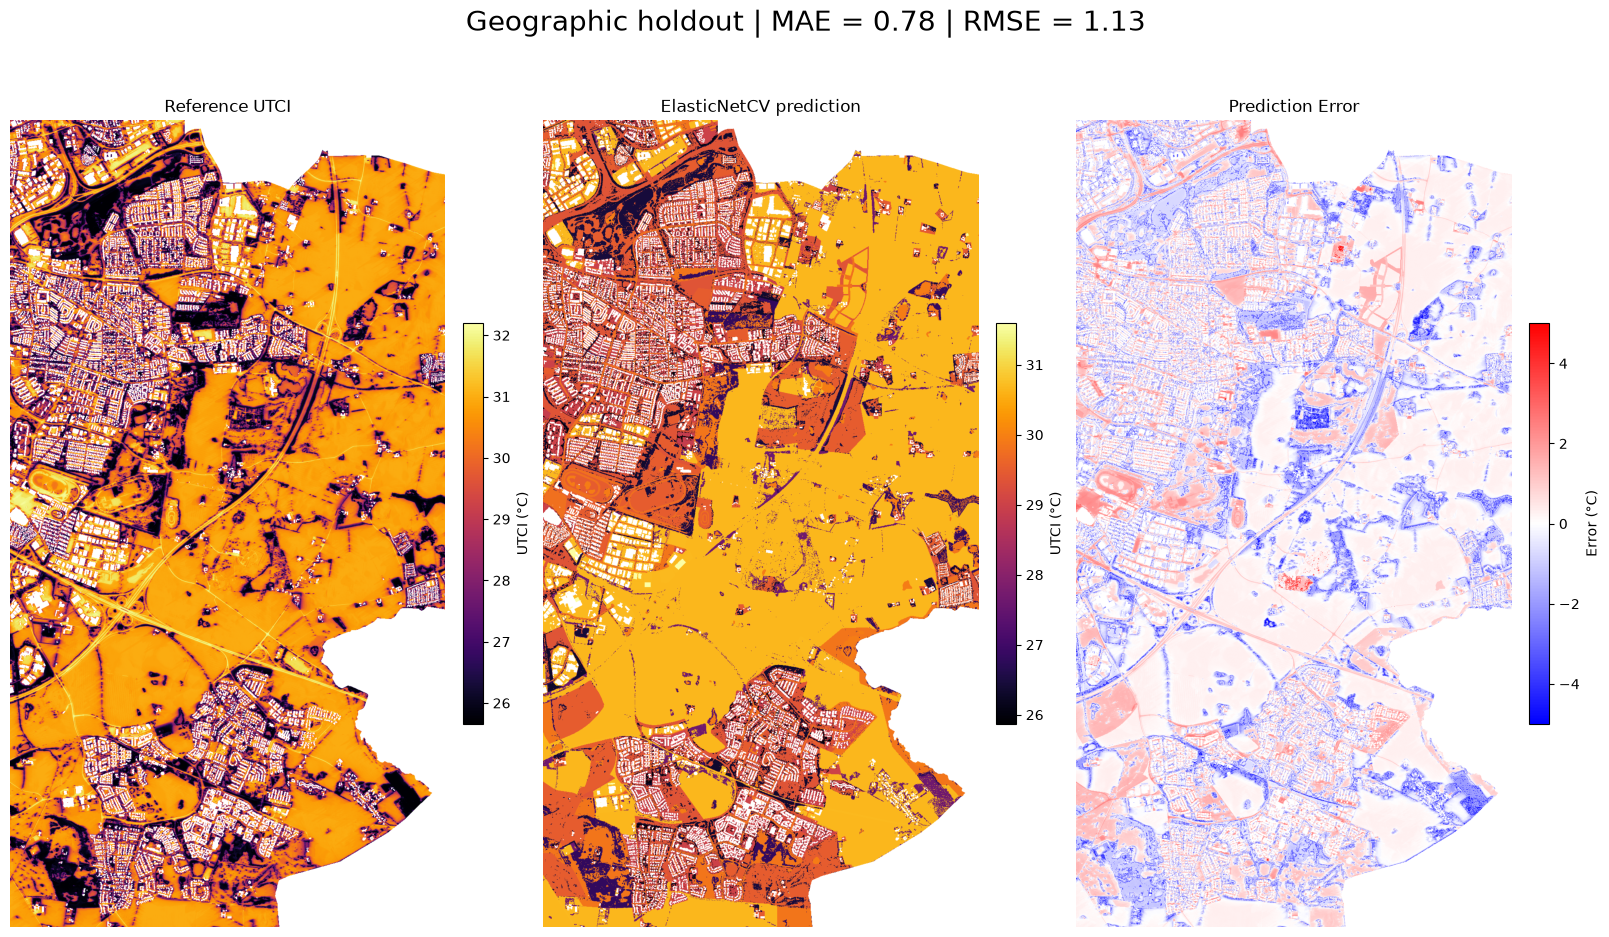

In [11]:
# 1. Initialize full 2D grids filled with NaNs for the whole raster area
obs_grid = np.full((height, width), np.nan)
pred_grid = np.full((height, width), np.nan)
error_grid = np.full((height, width), np.nan)


# 2. Calculate errors for the test set (Actual - Predicted)
y_errors = y_test - y_pred

# 3. Map the test predictions and errors back into their exact 2D pixel locations
# (test_mask is 1D, so we map it back to the 2D grid using the valid 2D test indices)
test_indices_2d = np.where(test_mask.reshape(height, width))
obs_grid[test_indices_2d] = y_test
pred_grid[test_indices_2d] = y_pred
error_grid[test_indices_2d] = y_errors

# 4. Crop to the hold-out region so the plotted data fills the figure
rows, cols = test_indices_2d
row_min, row_max = rows.min(), rows.max() + 1
col_min, col_max = cols.min(), cols.max() + 1
obs_crop = obs_grid[row_min:row_max, col_min:col_max]
pred_crop = pred_grid[row_min:row_max, col_min:col_max]
error_crop = error_grid[row_min:row_max, col_min:col_max]

fig, axes = plt.subplots(1, 3, figsize=(16, 10), constrained_layout=True)

# Plot Observed UTCI on the hold-out area
im1 = axes[0].imshow(obs_crop, cmap='inferno')
axes[0].set_title("Reference UTCI")
fig.colorbar(im1, ax=axes[0], label="UTCI (°C)", fraction=0.046, pad=0.04)

# Plot Predicted UTCI on the hold-out area
im2 = axes[1].imshow(pred_crop, cmap='inferno')
axes[1].set_title("ElasticNetCV prediction")
fig.colorbar(im2, ax=axes[1], label="UTCI (°C)", fraction=0.046, pad=0.04)

# Plot Error (Residuals)
# Diverging colormap ('coolwarm') is great for errors: 
# Red = Overpredicted, Blue = Underpredicted, White = Perfect
im3 = axes[2].imshow(error_crop, cmap='bwr', vmin=-5, vmax=5)
axes[2].set_title("Prediction Error")
fig.colorbar(im3, ax=axes[2], label="Error (°C)", fraction=0.046, pad=0.04)


for ax in axes:
    ax.axis('off')
plt.suptitle(f'Geographic holdout | MAE = {mae:.2f} | RMSE = {rmse:.2f}', fontsize=20)
plt.show()

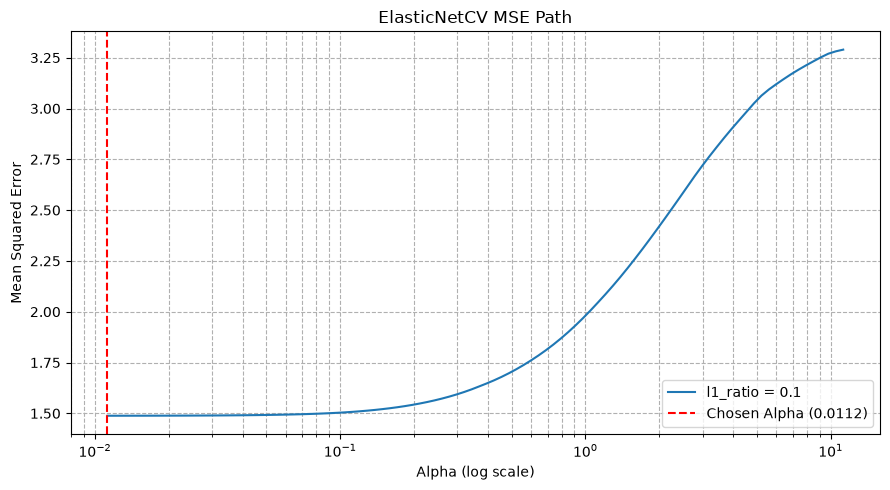

In [16]:
alphas = model.alphas_
mse_path = model.mse_path_

plt.figure(figsize=(9, 5))

# Check if mse_path is 2D (single l1_ratio) or 3D (multiple l1_ratios)
if mse_path.ndim == 2:
    mean_mse = mse_path.mean(axis=-1)
    plt.plot(alphas, mean_mse, label=f"l1_ratio = {model.l1_ratio_}")
else:
    l1_ratios = np.atleast_1d(model.l1_ratio_)
    for i, l1 in enumerate(l1_ratios):
        mean_mse = mse_path[i].mean(axis=-1)
        # Use alphas[i] to match the specific l1_ratio path
        plt.plot(alphas[i], mean_mse, label=f"l1_ratio = {l1}")

# Highlight the chosen optimal alpha
plt.axvline(model.alpha_, color="red", linestyle="--", label=f"Chosen Alpha ({model.alpha_:.4f})")

plt.xscale("log")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Mean Squared Error")
plt.title("ElasticNetCV MSE Path")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.tight_layout()
plt.show()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
C:\Users\vanme\AppData\Local\Temp\ipykernel_9196\2388836652.py:22: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
c:\Users\vanme\anaconda3\envs\modern_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


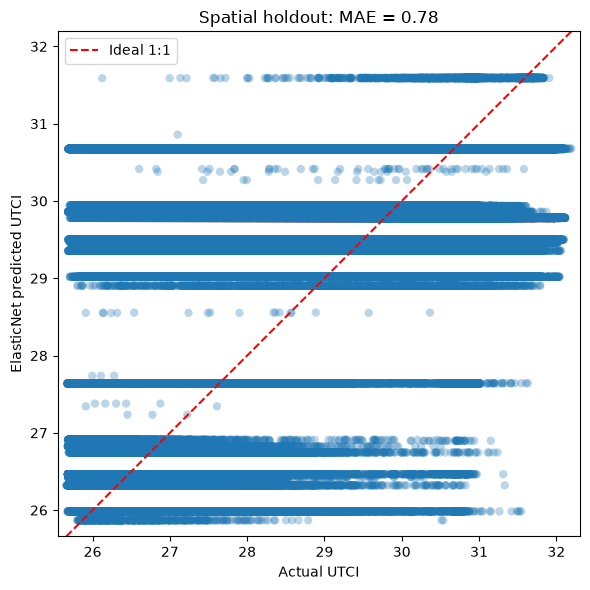

In [11]:
# Flatten to ensure 1D arrays
y_test_flat = np.asarray(y_test).ravel()
y_pred_flat = np.asarray(y_pred).ravel()

plt.figure(figsize=(6, 6))
plt.scatter(y_test_flat, y_pred_flat, alpha=0.3, edgecolors="none")

# Add 1:1 ideal line
min_val = min(min(y_test_flat), min(y_pred_flat))
max_val = max(max(y_test_flat), max(y_pred_flat))
plt.plot(
    [min_val, max_val], [min_val, max_val], color="red", linestyle="--", label="Ideal 1:1"
)

plt.xlabel("Actual UTCI")
plt.ylabel("ElasticNet predicted UTCI")
plt.title(f"Spatial holdout: MAE = {mae:.2f}")
plt.legend()
plt.axis("equal")
plt.xlim([min_val, max_val])
plt.ylim([min_val, max_val])
plt.tight_layout()
plt.show()


In [17]:
model.coef_

array([ 0.06125794, -0.93924136, -0.3037972 , -0.03086696,  0.2547324 ,
       -0.10963   , -0.00694297, -0.16927155,  0.37906466, -0.06915514,
       -0.03879633,  0.01009027])

# Climate Scenario Left-Out: Leave-One-Scenario-Out Evaluation

In this part, the model will be trained on different climate scenarios, and tested on unseen climate data in a 10-fold LOO approach. 

The experiment includes 10 present-day and future climate scenarios covering hot and normal summer conditions, the RCP4.5 and RCP8.5 pathways, and projections for 2050 and 2100. The static predictors are the same as in the previous spatial setup. Added to this are now 10 temperature regimes, of which 9 are used for training and 1 used for testing.

In [ ]:
import os
import pickle
import gc
import numpy as np
import rasterio
from sklearn.linear_model import ElasticNetCV
from sklearn.metrics import mean_absolute_error

feature_paths = [
    "data/processed_5m/input/building_presence_5m.tif",
    "data/processed_5m/input/canopy_presence_5m.tif",
    "data/processed_5m/input/landuse_bostadsbebyggelse_5m.tif",
    "data/processed_5m/input/landuse_h_rdgjord_mark_5m.tif",
    "data/processed_5m/input/landuse_industrimark_5m.tif",
    "data/processed_5m/input/landuse_kyrkog_rd_5m.tif",
    "data/processed_5m/input/landuse_naturomr_de_5m.tif",
    "data/processed_5m/input/landuse_park-_gr_nomr_de_5m.tif",
    "data/processed_5m/input/landuse_ppen_mark_5m.tif",
    "data/processed_5m/input/landuse_s_rskilda_fritidsomr_den_5m.tif",
    "data/processed_5m/input/landuse_tomtmark_5m.tif",
    "data/processed_5m/input/landuse_vatten_5m.tif"
]

utci_paths = [
    "data/processed_5m/target/1994-07-26_UTCI_present_hot_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP45_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP85_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_current_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP45_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP85_2100_5m_malmo_boundary.tif"
]

climate_paths = [
    "data/processed_5m/future_adjusted/1994-07-26_temperature_C.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP45_2050.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP45_2100.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP85_2050.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP85_2100.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_C.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP45_2050.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP45_2100.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP85_2050.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP85_2100.tif"
]

# Adjust this fraction if needed (0.1 means keep 10% of pixels randomly)
SAMPLE_FRACTION = 0.01 
print(f"Loading static features...")
static_features = []
for f_path in feature_paths:
    with rasterio.open(f_path) as src:
        static_features.append(src.read(1).ravel().astype(np.int8))

X_static_all = np.column_stack(static_features)
del static_features
gc.collect()

X_scenarios = []
y_scenarios = []
groups = []

print("Processing climate scenarios with subsampling...")
for fold_idx, (clim_path, utci_path) in enumerate(zip(climate_paths, utci_paths)):
    with rasterio.open(clim_path) as src_c, rasterio.open(utci_path) as src_u:
        clim_img = src_c.read(1)
        utci_img = src_u.read(1)
        
        nodata_c = src_c.nodata if src_c.nodata is not None else -9999
        nodata_u = src_u.nodata if src_u.nodata is not None else -9999
        
        valid = (clim_img != nodata_c) & (utci_img != nodata_u)
        valid_indices = np.where(valid.ravel())[0]
        
        # Subsample indices to save memory
        if SAMPLE_FRACTION < 1.0:
            rng = np.random.default_rng(seed=42)
            valid_indices = rng.choice(
                valid_indices, 
                size=int(len(valid_indices) * SAMPLE_FRACTION), 
                replace=False
            )
            valid_indices.sort() # Keep spatial order somewhat intact
            
        clim_flat = clim_img.ravel()[valid_indices].reshape(-1, 1).astype(np.float32)
        static_valid = X_static_all[valid_indices].astype(np.float32)
        
        X_combined = np.hstack([clim_flat, static_valid])
        
        X_scenarios.append(X_combined)
        y_scenarios.append(utci_img.ravel()[valid_indices].astype(np.float32))
        groups.append(np.full(len(valid_indices), fold_idx, dtype=np.int8))

del X_static_all
gc.collect()

X = np.vstack(X_scenarios)
y = np.concatenate(y_scenarios)
groups = np.concatenate(groups)

del X_scenarios, y_scenarios
gc.collect()

print(f"Final training matrix shape: {X.shape}")

def train_and_evaluate_logo_cv(X, y, groups, output_dir="outputs/spatial_left_out/checkpoints"):
    os.makedirs(output_dir, exist_ok=True)
    unique_groups = np.unique(groups)
    results = {}
    
    for test_group in unique_groups:
        train_idx = groups != test_group
        test_idx = groups == test_group
        
        X_train, y_train = X[train_idx], y[train_idx]
        X_test, y_test = X[test_idx], y[test_idx]
        
        model = ElasticNetCV(
            l1_ratio=[0.1, 0.5, 0.9],
            cv=3,
            random_state=42,
            n_jobs=1,
            precompute=False,  # <--- Add this line to bypass the float32 Gram matrix validation error
            selection='random'
        )
        
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        mae = mean_absolute_error(y_test, y_pred)
        
        results[test_group] = {
            "mae": mae,
            "model": model,
            "y_test": y_test,
            "y_pred": y_pred,

        }
        
        model_path = os.path.join(output_dir, f"ElasticNetCV_scenario_{test_group}.pkl")
        with open(model_path, "wb") as f:
            pickle.dump(model, f)
            
        print(f"Scenario {test_group} -> MAE: {mae:.4f} | Alpha: {model.alpha_:.4f} | L1: {model.l1_ratio_}")
        
    return results

cv_results = train_and_evaluate_logo_cv(X, y, groups)

Loading static features...
Processing climate scenarios with subsampling...
Final training matrix shape: (553790, 13)
Scenario 0 -> MAE: 1.0159 | Alpha: 0.0110 | L1: 0.9
Scenario 1 -> MAE: 0.9158 | Alpha: 0.0104 | L1: 0.9
Scenario 2 -> MAE: 0.8432 | Alpha: 0.0100 | L1: 0.9
Scenario 3 -> MAE: 1.0522 | Alpha: 0.0097 | L1: 0.9
Scenario 4 -> MAE: 0.9360 | Alpha: 0.0076 | L1: 0.9
Scenario 5 -> MAE: 1.1948 | Alpha: 0.0071 | L1: 0.9
Scenario 6 -> MAE: 1.0572 | Alpha: 0.0099 | L1: 0.9
Scenario 7 -> MAE: 1.0081 | Alpha: 0.0103 | L1: 0.9
Scenario 8 -> MAE: 1.0803 | Alpha: 0.0105 | L1: 0.9
Scenario 9 -> MAE: 1.1522 | Alpha: 0.0110 | L1: 0.9
